# EV Depot Charging with QAOA

**Problem.** A depot charges several electric vehicles overnight. Cheap hours are attractive, but putting every vehicle on the same hours creates a demand peak, and stopping and restarting a charge wears the battery. We encode this scheduling problem as a QUBO / Ising Hamiltonian and solve it with a constraint-preserving QAOA (an XY mixer), first in simulation (Part A) and then on a real IBM quantum computer (Part B).

**Decision variables.** $x_{v,t}=1$ if vehicle $v$ charges in time slot $t$. Vehicle $v$ needs exactly $k_v$ charging slots. With $V$ vehicles and $T$ slots we need $n=VT$ qubits, and the index convention `qubit = v*T + t` is used everywhere.

**Three objectives (all minimised).**
- Cost: $f_1=\sum_{v,t}\text{price}_t\,x_{v,t}$
- Peak proxy: $f_2=\sum_t\big(\sum_v x_{v,t}\big)^2$
- Battery wear (number of start/stop switches): $f_3=\sum_v\sum_t |x_{v,t}-x_{v,t+1}|$

**Instance used throughout.** 3 vehicles, 4 slots, prices (4, 1, 1, 3), each vehicle needs 2 slots. This gives 216 valid schedules and a 7-point Pareto front, so we can enumerate everything by brute force and use it as ground truth.

**Honest framing.** With only 216 valid schedules a laptop solves this exactly, so we claim no quantum speedup. The questions are: does a constraint-preserving ansatz keep every sample valid, how close does QAOA get to the optimum, and how much of that survives noise on real hardware?

In [ ]:
!pip install numpy pytest

In [34]:
from dataclasses import dataclass
from itertools import combinations, product
import numpy as np

@dataclass(frozen=True)
class Instance:
    V: int          # Number of vehicles
    T: int          # Number of time slots
    prices: tuple   # Electricity price for each slot (length T)
    need: tuple     # Number of charging slots needed by each vehicle (length V)

    @property
    def n(self):
        return self.V * self.T  # Total binary decisions = total qubits needed

def objectives(inst, x):
    '''
    x: Binary array of length V*T (1 = charging, 0 = idle).
    Index mapping rule: qubit index = v * T + t.
    Returns: (cost, peak, wear)
    '''
    X = np.asarray(x).reshape(inst.V, inst.T)
    cost = int((X * np.array(inst.prices)).sum())
    peak = int((X.sum(axis=0) ** 2).sum())
    wear = int(np.abs(np.diff(X, axis=1)).sum())
    return cost, peak, wear

def all_feasible(inst):
    '''Generates every valid schedule where vehicle v gets exactly need[v] charging slots.'''
    per_vehicle = []
    for v in range(inst.V):
        rows = []
        for slots in combinations(range(inst.T), inst.need[v]):
            r = np.zeros(inst.T, dtype=int)
            r[list(slots)] = 1
            rows.append(r)
        per_vehicle.append(rows)
    for combo in product(*per_vehicle):
        yield np.concatenate(combo)

def pareto_front(points):
    '''Filters objective triples to return only non-dominated (Pareto-optimal) schedules.'''
    pts = sorted(set(points))
    return [p for p in pts
            if not any(q != p and all(a <= b for a, b in zip(q, p)) for q in pts)]

def objective_scales(inst):
    '''Finds the worst-case values across valid schedules (used to normalize values).'''
    F = np.array([objectives(inst, x) for x in all_feasible(inst)])
    return F.max(axis=0)
def is_feasible(inst, x):
    '''True only if vehicle v charges in exactly need[v] slots.'''
    X = np.asarray(x).reshape(inst.V, inst.T)
    return all(X[v].sum() == inst.need[v] for v in range(inst.V))    
                

In [35]:
def test_example_matches_hand_calculation():
    # 3 vehicles, 4 time slots, prices (4, 1, 1, 3), each needs 2 slots
    inst = Instance(V=3, T=4, prices=(4, 1, 1, 3), need=(2, 2, 2))
    
    scheds = list(all_feasible(inst))
    assert len(scheds) == 216, f"Expected 216 feasible schedules, got {len(scheds)}"
    
    front = pareto_front([objectives(inst, x) for x in scheds])
    assert len(front) == 7, f"Expected 7 Pareto front points, got {len(front)}"
    assert (6, 18, 6) in front and (11, 10, 4) in front
    
    print("SUCCESS: Step 1 test passed! Total schedules = 216, Pareto front size = 7")

# Run the test
test_example_matches_hand_calculation()

SUCCESS: Step 1 test passed! Total schedules = 216, Pareto front size = 7


Step 2: Write Objectives as a QUBO Matrix

In [36]:
import numpy as np

def build_qubo(inst, lam=(1, 1, 1), scale=(1, 1, 1), penalty=0.0):
    '''
    Builds matrix Q and constant c such that f(x) = x @ Q @ x + c.
    Q is upper-triangular.
    '''
    V, T, n = inst.V, inst.T, inst.n
    l1, l2, l3 = (l / s for l, s in zip(lam, scale))
    q = lambda v, t: v * T + t
    Q = np.zeros((n, n))
    const = 0.0

    # 1. Cost Objective
    for v in range(V):
        for t in range(T):
            Q[q(v, t), q(v, t)] += l1 * inst.prices[t]

    # 2. Peak Proxy Objective
    for t in range(T):
        for v in range(V):
            Q[q(v, t), q(v, t)] += l2
            for w in range(v + 1, V):
                Q[q(v, t), q(w, t)] += 2 * l2

    # 3. Battery Wear Objective
    for v in range(V):
        for t in range(T - 1):
            Q[q(v, t), q(v, t)] += l3
            Q[q(v, t + 1), q(v, t + 1)] += l3
            Q[q(v, t), q(v, t + 1)] += -2 * l3

    # Optional: Penalty term for Option A (fixed slot constraint)
    if penalty:
        for v in range(V):
            k = inst.need[v]
            for t in range(T):
                Q[q(v, t), q(v, t)] += penalty * (1 - 2 * k)
                for s in range(t + 1, T):
                    Q[q(v, t), q(v, s)] += 2 * penalty
            const += penalty * k * k

    return Q, const

In [37]:
def test_qubo_matches_objectives():
    inst = Instance(3, 4, (4, 1, 1, 3), (2, 2, 2))
    scale = objective_scales(inst)
    lam = (0.5, 0.3, 0.2)  # Test with arbitrary objective weights
    
    Q, c = build_qubo(inst, lam, scale)
    
    # Check that for all 216 valid schedules, x @ Q @ x + c matches the objective sum exactly
    for x in all_feasible(inst):
        expected = sum(l * f / s for l, f, s in zip(lam, objectives(inst, x), scale))
        actual = x @ Q @ x + c
        assert abs(actual - expected) < 1e-9, f"Mismatch: expected {expected}, got {actual}"
        
    print(" SUCCESS: Step 2 test passed! QUBO matrix perfectly matches objective scores across all 216 schedules.")

# Run the test
test_qubo_matches_objectives()

 SUCCESS: Step 2 test passed! QUBO matrix perfectly matches objective scores across all 216 schedules.


step 3 : QUBO to Hmaltonian conversion

In [38]:
from qiskit.quantum_info import SparsePauliOp

def qubo_to_hamiltonian(Q, const=0.0):
    '''
    Converts QUBO (Q, const) into a Qiskit SparsePauliOp Cost Hamiltonian H_C
    using the mapping x_i = (I - Z_i)/2.
    '''
    n = Q.shape[0]
    pauli_list = []

    # 1. Constant term offset from conversion
    # x_i = 1/2 I - 1/2 Z_i
    # x_i x_j = 1/4 I - 1/4 Z_i - 1/4 Z_j + 1/4 Z_i Z_j
    offset = const

    # Single qubit terms (Diagonal of Q)
    for i in range(n):
        q_ii = Q[i, i]
        if q_ii != 0:
            offset += q_ii / 2.0
            # Add -q_ii/2 * Z_i
            z_string = ['I'] * n
            z_string[n - 1 - i] = 'Z'  # Qiskit uses little-endian ordering
            pauli_list.append((''.join(z_string), -q_ii / 2.0))

    # Two-qubit interaction terms (Upper triangle of Q)
    for i in range(n):
        for j in range(i + 1, n):
            q_ij = Q[i, j]
            if q_ij != 0:
                offset += q_ij / 4.0
                
                # -q_ij/4 * Z_i
                z_i = ['I'] * n
                z_i[n - 1 - i] = 'Z'
                pauli_list.append((''.join(z_i), -q_ij / 4.0))

                # -q_ij/4 * Z_j
                z_j = ['I'] * n
                z_j[n - 1 - j] = 'Z'
                pauli_list.append((''.join(z_j), -q_ij / 4.0))

                # +q_ij/4 * Z_i Z_j
                z_ij = ['I'] * n
                z_ij[n - 1 - i] = 'Z'
                z_ij[n - 1 - j] = 'Z'
                pauli_list.append((''.join(z_ij), q_ij / 4.0))

    # Constant identity term
    id_string = 'I' * n
    pauli_list.append((id_string, offset))

    # Combine like terms and build SparsePauliOp
    return SparsePauliOp.from_list(pauli_list).simplify()

In [39]:
def test_hamiltonian_eigenvalues_match_qubo():
    inst = Instance(3, 4, (4, 1, 1, 3), (2, 2, 2))
    scale = objective_scales(inst)
    lam = (0.5, 0.3, 0.2)
    
    Q, c = build_qubo(inst, lam, scale)
    H_C = qubo_to_hamiltonian(Q, c)
    
    # Verify energy for a sample schedule x
    sample_x = next(all_feasible(inst))
    qubo_energy = sample_x @ Q @ sample_x + c
    
    # Calculate expectation value directly from Pauli terms for state |x>
    bitstring = "".join(str(b) for b in sample_x)
    
    # Evaluate Pauli Z expectation on bitstring
    pauli_energy = 0.0
    for label, coeff in H_C.label_iter():
        val = coeff.real
        for idx, char in enumerate(reversed(label)):
            if char == 'Z' and bitstring[idx] == '1':
                val *= -1.0
        pauli_energy += val

    assert abs(qubo_energy - pauli_energy) < 1e-7, f"Mismatch: QUBO {qubo_energy} vs Pauli {pauli_energy}"
    print(f" SUCCESS: Step 3 test passed! Pauli Hamiltonian energy ({pauli_energy:.4f}) matches QUBO energy ({qubo_energy:.4f}).")

# Run the test
test_hamiltonian_eigenvalues_match_qubo()

 SUCCESS: Step 3 test passed! Pauli Hamiltonian energy (0.7238) matches QUBO energy (0.7238).


Step 4 (revised): Constraint-preserving QAOA (XY mixer)


In [40]:
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import XXPlusYYGate, StatePreparation

def dicke_vector(T, k):
    '''Equal superposition of all T-bit strings with exactly k ones.'''
    vec = np.zeros(2 ** T)
    for slots in combinations(range(T), k):
        vec[sum(1 << t for t in slots)] = 1.0
    return vec / np.linalg.norm(vec)

def start_state(qc, inst, kind='dicke'):
    for v in range(inst.V):
        reg = [v * inst.T + t for t in range(inst.T)]
        if kind == 'dicke':                      # simulation
            qc.append(StatePreparation(dicke_vector(inst.T, inst.need[v])), reg)
        else:                                    # 'basis': X gates only, hardware-friendly
            for t in range(inst.need[v]):
                qc.x(reg[t])

def cost_layer(qc, H_cost, gamma):
    '''exp(-i*gamma*H) written as explicit RZ / RZZ gates (H has only Z and ZZ terms).'''
    for label, coeff in H_cost.to_list():
        zs = [i for i, ch in enumerate(reversed(label)) if ch == 'Z']  # qubit 0 = rightmost
        w = 2 * coeff.real * gamma
        if len(zs) == 1:
            qc.rz(w, zs[0])
        elif len(zs) == 2:
            qc.rzz(w, zs[0], zs[1])
        # identity term is only a global phase, so it is skipped

def xy_mixer(qc, inst, beta):
    '''Swaps a 1 and a 0 between neighbouring slots of the SAME vehicle only.'''
    for v in range(inst.V):
        base = v * inst.T
        for start in (0, 1):
            for t in range(start, inst.T - 1, 2):
                qc.append(XXPlusYYGate(2 * beta), [base + t, base + t + 1])

def x_mixer(qc, inst, beta):
    for q in range(inst.n):
        qc.rx(2 * beta, q)

def build_qaoa(inst, H_cost, p, mixer='xy', start='dicke'):
    gam, bet = ParameterVector('gamma', p), ParameterVector('beta', p)
    qc = QuantumCircuit(inst.n)
    if mixer == 'xy':
        start_state(qc, inst, start)
    else:
        qc.h(range(inst.n))
    for l in range(p):
        cost_layer(qc, H_cost, gam[l])
        (xy_mixer if mixer == 'xy' else x_mixer)(qc, inst, bet[l])
    return qc

In [41]:
from qiskit.quantum_info import Statevector

def test_xy_mixer_keeps_schedules_valid():
    inst = Instance(3, 4, (4, 1, 1, 3), (2, 2, 2))
    Q, c = build_qubo(inst, (0.5, 0.3, 0.2), objective_scales(inst))
    H = qubo_to_hamiltonian(Q, c)
    circ = build_qaoa(inst, H, p=2)
    print("Parameter order:", [p.name for p in circ.parameters])   # keep this line
    theta = np.random.default_rng(1).uniform(0, 3, 4)
    probs = Statevector(circ.assign_parameters(theta)).probabilities_dict()
    for key, pr in probs.items():
        if pr > 1e-12:
            x = np.array([int(b) for b in key[::-1]])             # qubit 0 = rightmost char
            assert is_feasible(inst, x), f"Invalid schedule reached: {key}"
    print(" XY mixer never leaves the valid schedules")

def test_zero_angles_give_mean_valid_energy():
    inst = Instance(3, 4, (4, 1, 1, 3), (2, 2, 2))
    Q, c = build_qubo(inst, (0.5, 0.3, 0.2), objective_scales(inst))
    H = qubo_to_hamiltonian(Q, c)
    circ = build_qaoa(inst, H, p=2)
    e0 = Statevector(circ.assign_parameters(np.zeros(4))).expectation_value(H).real
    mean_valid = np.mean([x @ Q @ x + c for x in all_feasible(inst)])
    assert abs(e0 - mean_valid) < 1e-9
    print(f" Zero-angle energy {e0:.4f} equals the mean over 216 valid schedules")

test_xy_mixer_keeps_schedules_valid()
test_zero_angles_give_mean_valid_energy()

Parameter order: ['beta[0]', 'beta[1]', 'gamma[0]', 'gamma[1]']
 XY mixer never leaves the valid schedules
 Zero-angle energy 0.6548 equals the mean over 216 valid schedules


Blind-guess average: 0.6548 | True optimum: 0.5175
p=1 | energy 0.6394 | approx_ratio 0.707 | P(optimal) 0.030 | feasible 100.0%
p=2 | energy 0.5742 | approx_ratio 0.864 | P(optimal) 0.169 | feasible 100.0%
p=3 | energy 0.5695 | approx_ratio 0.875 | P(optimal) 0.169 | feasible 100.0%


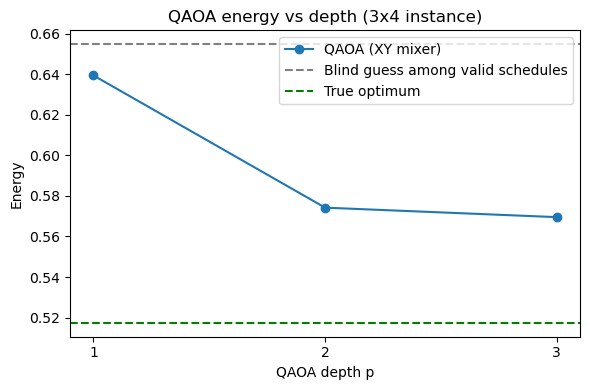

In [42]:
import os, json
from scipy.optimize import minimize
import matplotlib.pyplot as plt

inst = Instance(3, 4, (4, 1, 1, 3), (2, 2, 2))
scale, lam = objective_scales(inst), (0.5, 0.3, 0.2)
Q, c = build_qubo(inst, lam, scale)
H = qubo_to_hamiltonian(Q, c)

# Baselines from brute force over the 216 valid schedules
valid_vals = np.array([x @ Q @ x + c for x in all_feasible(inst)])
E_mean, E_best, E_worst = valid_vals.mean(), valid_vals.min(), valid_vals.max()
print(f"Blind-guess average: {E_mean:.4f} | True optimum: {E_best:.4f}")

def make_energy(circ):
    return lambda theta: Statevector(circ.assign_parameters(theta)).expectation_value(H).real

def optimise(f, p, restarts=3, maxiter=300, seed=0, x_init=None):
    rng = np.random.default_rng(seed)
    best = None
    for r in range(restarts):
        x0 = x_init if (x_init is not None and r == 0) else rng.uniform(0, np.pi, 2 * p)
        res = minimize(f, x0, method='COBYLA', options={'maxiter': maxiter})
        if best is None or res.fun < best.fun:
            best = res
    return best

results, prev = {}, None
for p in (1, 2, 3):
    circ = build_qaoa(inst, H, p, mixer='xy', start='dicke')
    # warm start: previous optimum with zero angles appended (order: betas then gammas)
    x_init = None if prev is None else np.concatenate([prev[:p-1], [0.0], prev[p-1:], [0.0]])
    res = optimise(make_energy(circ), p, x_init=x_init)
    prev = res.x
    probs = Statevector(circ.assign_parameters(res.x)).probabilities_dict()
    xs = {k: np.array([int(b) for b in k[::-1]]) for k in probs}
    feasible_rate = sum(pr for k, pr in probs.items() if is_feasible(inst, xs[k]))
    p_opt = sum(pr for k, pr in probs.items() if abs(xs[k] @ Q @ xs[k] + c - E_best) < 1e-9)
    results[p] = dict(theta=res.x.tolist(), energy=float(res.fun),
                      approx_ratio=float((E_worst - res.fun) / (E_worst - E_best)),
                      p_optimal=float(p_opt), feasible_rate=float(feasible_rate))
    print(f"p={p} | energy {res.fun:.4f} | approx_ratio {results[p]['approx_ratio']:.3f} "
          f"| P(optimal) {p_opt:.3f} | feasible {feasible_rate*100:.1f}%")

os.makedirs('results', exist_ok=True)
json.dump(dict(E_mean=E_mean, E_best=E_best, E_worst=E_worst, by_p=results),
          open('results/qaoa_xy_3x4_params.json', 'w'), indent=2)

# Figure: energy vs depth against the baselines
ps = list(results)
plt.figure(figsize=(6, 4))
plt.plot(ps, [results[p]['energy'] for p in ps], 'o-', label='QAOA (XY mixer)')
plt.axhline(E_mean, color='gray', ls='--', label='Blind guess among valid schedules')
plt.axhline(E_best, color='green', ls='--', label='True optimum')
plt.xticks(ps); plt.xlabel('QAOA depth p'); plt.ylabel('Energy')
plt.title('QAOA energy vs depth (3x4 instance)'); plt.legend(); plt.tight_layout()
os.makedirs('results', exist_ok=True); plt.savefig('results/energy_vs_depth.png', dpi=150); plt.show()

## Part A results: QAOA with XY mixer, ideal simulation (3 vehicles × 4 slots)
Angles come from the optimisation above (`results/qaoa_xy_3x4_params.json`). We draw 4096 shots from the circuit, decode each bitstring, and re-score every schedule with the plain objective functions, never with the Hamiltonian.

In [43]:
import json
from qiskit.quantum_info import Statevector

def decode_bitstring(bitstring, inst):
    '''Qiskit prints qubit 0 on the RIGHT, so reverse first. Returns the V x T schedule matrix.'''
    x = np.array([int(b) for b in bitstring[::-1]])
    return x.reshape(inst.V, inst.T)

P_FINAL, SHOTS = 3, 4096
saved = json.load(open('results/qaoa_xy_3x4_params.json'))
theta = np.array(saved['by_p'][str(P_FINAL)]['theta'])      # order: betas then gammas
print(f"Loaded p={P_FINAL} angles from results/qaoa_xy_3x4_params.json: {np.round(theta, 4)}")

circ = build_qaoa(inst, H, P_FINAL, mixer='xy', start='dicke')
# Ideal (noise-free) simulation: sample finite shots from the exact final state.
# No transpile step is needed, which also avoids a basis-translator bug in some Qiskit versions.
state = Statevector(circ.assign_parameters(theta))
state.seed(7)
counts = {str(k): int(v) for k, v in state.sample_counts(SHOTS).items()}

# Score every sampled schedule classically with the plain objective functions
rows = []
for bstr, n in counts.items():
    x = np.array([int(b) for b in bstr[::-1]])
    rows.append(dict(bitstring=bstr, shots=n, feasible=is_feasible(inst, x),
                     score=float(x @ Q @ x + c), objs=objectives(inst, x)))

feasible_rate = sum(r['shots'] for r in rows if r['feasible']) / SHOTS
mean_sampled = sum(r['score'] * r['shots'] for r in rows) / SHOTS
n_opt = int(np.sum(np.abs(valid_vals - E_best) < 1e-9))
p_opt_sampled = sum(r['shots'] for r in rows if abs(r['score'] - E_best) < 1e-9) / SHOTS

print(f"\nShots: {SHOTS} | distinct schedules sampled: {len(rows)}")
print(f"Feasible rate:          {feasible_rate*100:.1f}%   (random bitstrings would give 5.3%)")
print(f"Mean weighted score:    {mean_sampled:.4f}   (blind guess among valid: {E_mean:.4f}, optimum: {E_best:.4f})")
print(f"P(sample is optimal):   {p_opt_sampled*100:.1f}%   (blind guess among valid: {n_opt/216*100:.1f}%, {n_opt} optimal schedules)")

top = sorted(rows, key=lambda r: -r['shots'])[:5]
print("\nTop 5 most frequent schedules:")
for r in top:
    print(f"  {r['bitstring']} | {r['shots']:4d} shots | score {r['score']:.4f} | "
          f"(cost, peak, wear) = {r['objs']}")

Loaded p=3 angles from results/qaoa_xy_3x4_params.json: [2.8392 3.8099 0.0321 5.3184 5.7194 0.0998]

Shots: 4096 | distinct schedules sampled: 149
Feasible rate:          100.0%   (random bitstrings would give 5.3%)
Mean weighted score:    0.5688   (blind guess among valid: 0.6548, optimum: 0.5175)
P(sample is optimal):   17.7%   (blind guess among valid: 2.8%, 6 optimal schedules)

Top 5 most frequent schedules:
  011001100110 |  319 shots | score 0.5762 | (cost, peak, wear) = (6, 18, 6)
  011001101100 |  200 shots | score 0.5349 | (cost, peak, wear) = (8, 14, 5)
  110001100110 |  193 shots | score 0.5349 | (cost, peak, wear) = (8, 14, 5)
  011011000110 |  181 shots | score 0.5349 | (cost, peak, wear) = (8, 14, 5)
  011000110110 |  180 shots | score 0.5587 | (cost, peak, wear) = (9, 14, 5)


Best sampled schedule: 001111000110 | score 0.5175 (optimum 0.5175) | cost=11, peak=10, wear=4
[[0 1 1 0]
 [0 0 1 1]
 [1 1 0 0]]


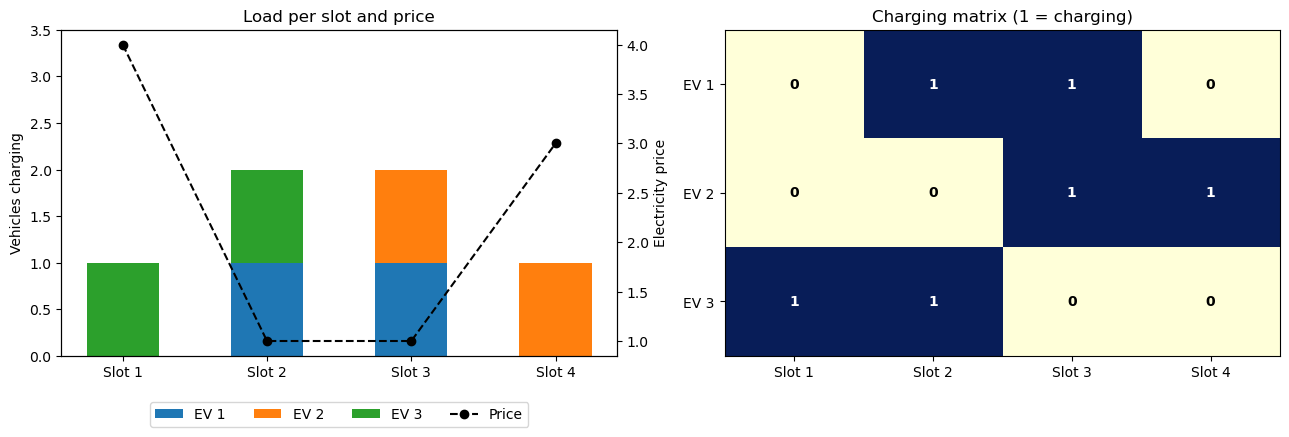

In [44]:
import matplotlib.pyplot as plt

best_row = min((r for r in rows if r['feasible']), key=lambda r: (r['score'], -r['shots']))
sched = decode_bitstring(best_row['bitstring'], inst)
cost_, peak_, wear_ = best_row['objs']
print(f"Best sampled schedule: {best_row['bitstring']} | score {best_row['score']:.4f} "
      f"(optimum {E_best:.4f}) | cost={cost_}, peak={peak_}, wear={wear_}")
print(sched)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
slots = [f"Slot {t+1}" for t in range(inst.T)]
bottom = np.zeros(inst.T)
for v in range(inst.V):
    ax1.bar(slots, sched[v], bottom=bottom, label=f"EV {v+1}", width=0.5)
    bottom += sched[v]
ax1.set_ylabel("Vehicles charging"); ax1.set_ylim(0, inst.V + 0.5)
ax2_twin = ax1.twinx()
ax2_twin.plot(slots, inst.prices, 'k--o', label='Price')
ax2_twin.set_ylabel("Electricity price")
ax1.set_title("Load per slot and price")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2_twin.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4)

im = ax2.imshow(sched, cmap="YlGnBu", aspect="auto", vmin=0, vmax=1)
ax2.set_xticks(range(inst.T)); ax2.set_xticklabels(slots)
ax2.set_yticks(range(inst.V)); ax2.set_yticklabels([f"EV {v+1}" for v in range(inst.V)])
for v in range(inst.V):
    for t in range(inst.T):
        ax2.text(t, v, str(sched[v, t]), ha='center', va='center',
                 color='white' if sched[v, t] else 'black', fontweight='bold')
ax2.set_title("Charging matrix (1 = charging)")
plt.tight_layout()
os.makedirs('results', exist_ok=True)
plt.savefig('results/best_schedule_3x4.png', dpi=150); plt.show()

PART B

## Step 1: Pre-flight check before spending QPU time
The hardware circuit uses the shallow `basis` start state (X gates only), because the Dicke start compiles to many more two-qubit gates. Its angles are re-trained below. We then count the two-qubit gates on the real backend layout and predict the hardware feasible rate with a noisy simulation.

In [45]:
import qiskit, qiskit_ibm_runtime
print("qiskit", qiskit.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

def sched_score(bitstring):
    x = np.array([int(b) for b in bitstring[::-1]])
    return float(x @ Q @ x + c)

# Energy of the 'basis' start state itself (all angles zero): this is the score of ONE fixed schedule
start_only = Statevector(build_qaoa(inst, H, 1, 'xy', 'basis').assign_parameters([0.0, 0.0]))
print(f"Basis start (angles = 0) energy: {start_only.expectation_value(H).real:.4f} "
      f"| blind guess {E_mean:.4f} | optimum {E_best:.4f}\n")

hw_params, prev = {}, None
for p in (1, 2):
    circ_hw = build_qaoa(inst, H, p, mixer='xy', start='basis')
    x_init = None if prev is None else np.concatenate([prev[:p-1], [0.0], prev[p-1:], [0.0]])
    res = optimise(make_energy(circ_hw), p, restarts=5, x_init=x_init)
    prev = res.x
    probs = Statevector(circ_hw.assign_parameters(res.x)).probabilities_dict()
    p_opt = sum(pr for k, pr in probs.items() if abs(sched_score(k) - E_best) < 1e-9)
    feas = sum(pr for k, pr in probs.items()
               if is_feasible(inst, np.array([int(b) for b in k[::-1]])))
    hw_params[p] = dict(theta=res.x.tolist(), energy=float(res.fun),
                        p_optimal=float(p_opt), feasible_rate=float(feas))
    print(f"basis start, p={p} | energy {res.fun:.4f} | P(optimal) {p_opt:.3f} | feasible {feas*100:.1f}%")

json.dump(hw_params, open('results/qaoa_xy_3x4_hw_params.json', 'w'), indent=2)

qiskit 2.3.1 | qiskit-ibm-runtime 0.50.0
Basis start (angles = 0) energy: 0.7238 | blind guess 0.6548 | optimum 0.5175

basis start, p=1 | energy 0.7183 | P(optimal) 0.000 | feasible 100.0%
basis start, p=2 | energy 0.6252 | P(optimal) 0.045 | feasible 100.0%


In [46]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.fake_provider import FakeFez

try:
    service = QiskitRuntimeService()               # uses the credentials saved on this machine
    backend = service.backend('ibm_fez')
    USING_REAL_BACKEND = True
except Exception as e:
    print(f"Could not reach ibm_fez ({type(e).__name__}); using the offline FakeFez snapshot instead.")
    backend = FakeFez()
    USING_REAL_BACKEND = False
print("Backend:", backend.name, "| real device:", USING_REAL_BACKEND)

def transpile_best(circuit, backend, seeds=range(5)):
    '''Transpile with several seeds and keep the circuit with the fewest two-qubit gates.'''
    best = None
    for s in seeds:
        pm = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=s,
                                  translation_method="translator")
        isa = pm.run(circuit)
        n2 = sum(v for k, v in isa.count_ops().items() if k in ('cz', 'ecr', 'cx'))
        if best is None or n2 < best[0]:
            best = (n2, isa)
    return best

isa_circuits, stats = {}, {}
print(f"\n{'p':>2} | {'2-qubit gates':>13} | {'depth':>5}")
for p in (1, 2):
    circ_hw = build_qaoa(inst, H, p, mixer='xy', start='basis')
    bound = circ_hw.assign_parameters(hw_params[p]['theta'])
    bound.measure_all()
    n2, isa = transpile_best(bound, backend)
    isa_circuits[p] = isa
    stats[p] = dict(two_qubit_gates=n2, depth=isa.depth(), backend=backend.name)
    print(f"{p:>2} | {n2:>13} | {isa.depth():>5}")

json.dump(stats, open('results/hw_circuit_stats.json', 'w'), indent=2)
print("\nRule of thumb: tens of two-qubit gates give informative output; several hundred drift toward noise.")

qiskit_runtime_service.__init__:WARNING:2026-10-05 01:14:41,881: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-05 01:14:41,882: Using instance: open-instance, plan: open


Backend: ibm_fez | real device: True

 p | 2-qubit gates | depth
 1 |           116 |   153
 2 |           245 |   297

Rule of thumb: tens of two-qubit gates give informative output; several hundred drift toward noise.


In [47]:
import json, os
from qiskit.quantum_info import Statevector, hellinger_fidelity

RESULTS = 'results'
os.makedirs(RESULTS, exist_ok=True)
NQ = inst.n
RANDOM_FEASIBLE_RATE = len(valid_vals) / 2 ** NQ          # 216 / 4096 = 5.3 %

def bits_to_x(bstr):
    """Qiskit prints qubit 0 on the RIGHT, so reverse first."""
    return np.array([int(b) for b in bstr[::-1]])

def clean(counts):
    """Plain {12-char bitstring: int} dict (strips spaces, pads leading zeros)."""
    return {k.replace(' ', '').zfill(NQ): int(v) for k, v in counts.items()}

def analyse(dist, label, exact=False, ideal=None):
    """Metrics of a counts dict (or of an exact probability dict if exact=True).
    Every bitstring is re-scored with the plain objective, never with the Hamiltonian."""
    total = sum(dist.values())
    s, w = [], []
    for k, v in dist.items():
        x = bits_to_x(k)
        if is_feasible(inst, x):
            s.append(float(x @ Q @ x + c)); w.append(v)
    s, w = np.array(s), np.array(w, dtype=float)
    n_ok = w.sum() if len(w) else 0.0
    out = dict(label=label, feasible_rate=float(n_ok / total))
    if n_ok > 0:
        mean = float((w * s).sum() / n_ok)
        out.update(post_mean=mean,
                   approx_ratio=float((E_worst - mean) / (E_worst - E_best)),
                   p_optimal_post=float(w[np.abs(s - E_best) < 1e-9].sum() / n_ok))
        if not exact:   # statistical error bars only make sense for finite shots
            sd = np.sqrt((w * (s - mean) ** 2).sum() / n_ok)
            out.update(post_mean_se=float(sd / np.sqrt(n_ok)), post_shots=int(n_ok),
                       feasible_se=float(np.sqrt(out['feasible_rate'] * (1 - out['feasible_rate']) / total)))
    if ideal is not None:
        out['hellinger_fid'] = float(hellinger_fidelity(ideal, dist))
    return out

def violation_hist(dist):
    """Share of shots by D = sum over vehicles of |charging slots - need|. D = 0 means a valid schedule."""
    dmax = sum(max(k, inst.T - k) for k in inst.need)
    h, total = np.zeros(dmax + 1), sum(dist.values())
    for k, v in dist.items():
        X = bits_to_x(k).reshape(inst.V, inst.T)
        h[int(np.abs(X.sum(axis=1) - np.array(inst.need)).sum())] += v
    return h / total

# Exact ideal distributions of the SAME circuits that go to the QPU
ideal = {}
for p in (1, 2):
    circ_p = build_qaoa(inst, H, p, mixer='xy', start='basis').assign_parameters(hw_params[p]['theta'])
    ideal[p] = {k: v for k, v in Statevector(circ_p).probabilities_dict().items() if v > 1e-12}

# Fully scrambled output: every one of the 2^12 bitstrings equally likely
uniform = {format(i, f'0{NQ}b'): 1.0 for i in range(2 ** NQ)}

for p in (1, 2):
    r = analyse(ideal[p], f'ideal p={p}', exact=True)
    print(f"ideal p={p}: feasible {r['feasible_rate']*100:.1f}% | mean score {r['post_mean']:.4f} | P(optimal) {r['p_optimal_post']:.3f}")
r = analyse(uniform, 'uniform noise', exact=True)
print(f"uniform noise: feasible {r['feasible_rate']*100:.1f}% | mean score of valid ones {r['post_mean']:.4f}  (= blind guess {E_mean:.4f})")

ideal p=1: feasible 100.0% | mean score 0.7183 | P(optimal) 0.000
ideal p=2: feasible 100.0% | mean score 0.6252 | P(optimal) 0.045
uniform noise: feasible 5.3% | mean score of valid ones 0.6548  (= blind guess 0.6548)


In [48]:
from qiskit_aer import AerSimulator

# True = run the noisy simulation now (a few minutes, p=2 takes longer); False = only load cached results
RUN_NOISY_SIM = True
NOISY_SHOTS = 2048

def active_qubits(circ):
    return len({circ.find_bit(q).index for ci in circ.data for q in ci.qubits})

noisy_counts = {}
for p in (1, 2):
    path = f'{RESULTS}/noisy_sim_counts_p{p}.json'
    if os.path.exists(path):
        noisy_counts[p] = clean(json.load(open(path)))
        print(f"p={p}: loaded cached noisy simulation ({sum(noisy_counts[p].values())} shots)")
        continue
    if not RUN_NOISY_SIM:
        continue
    n_act = active_qubits(isa_circuits[p])
    if n_act > 26:
        print(f"p={p}: {n_act} active qubits is too many for a noisy statevector simulation, skipped")
        continue
    print(f"p={p}: simulating {NOISY_SHOTS} shots on {n_act} active qubits ...")
    sim = AerSimulator.from_backend(backend)        # error rates of the chosen device
    res = sim.run(isa_circuits[p], shots=NOISY_SHOTS).result()
    noisy_counts[p] = clean(res.get_counts())
    json.dump(noisy_counts[p], open(path, 'w'))

p=1: loaded cached noisy simulation (2048 shots)
p=2: loaded cached noisy simulation (2048 shots)


In [49]:
import datetime, qiskit, qiskit_ibm_runtime
from qiskit_ibm_runtime import SamplerV2 as Sampler

# ---------------------------------------------------------------------------
# SWITCH:  True  = submit the jobs below to the real QPU (uses QPU time)
#          False = never touch the QPU, the analysis loads the saved counts in results/
# ---------------------------------------------------------------------------
RUN_ON_HARDWARE = True
SHOTS_HW = 4096
SUBMIT = ['p2_mit', 'p2_raw', 'p1_mit', 'p1_raw']        # shorten this list if your QPU budget is tight
RUN_CONFIG = {'p1_raw': (1, False), 'p1_mit': (1, True),   # run id -> (depth p, mitigation on?)
              'p2_raw': (2, False), 'p2_mit': (2, True)}

JOBS_FILE = f'{RESULTS}/hw_jobs.json'
jobs_info = json.load(open(JOBS_FILE)) if os.path.exists(JOBS_FILE) else {}

def make_sampler(backend, mitigated, shots):
    sampler = Sampler(mode=backend)
    sampler.options.default_shots = shots
    sampler.options.dynamical_decoupling.enable = mitigated
    sampler.options.twirling.enable_gates = mitigated
    sampler.options.twirling.enable_measure = mitigated
    if mitigated:
        sampler.options.dynamical_decoupling.sequence_type = 'XpXm'
        sampler.options.twirling.num_randomizations = 'auto'
    return sampler

if RUN_ON_HARDWARE:
    if not USING_REAL_BACKEND:
        raise RuntimeError("Not connected to a real backend (see the backend cell above). "
                           "Fix your IBM credentials or set RUN_ON_HARDWARE = False.")
    for run_id in SUBMIT:
        if run_id in jobs_info:
            print(f"{run_id}: already submitted as job {jobs_info[run_id]['job_id']}, skipping "
                  f"(delete its entry in {JOBS_FILE} to submit it again)")
            continue
        p, mit = RUN_CONFIG[run_id]
        job = make_sampler(backend, mit, SHOTS_HW).run([isa_circuits[p]])
        jobs_info[run_id] = dict(
            job_id=job.job_id(), backend=backend.name, p=p, mitigated=mit, shots=SHOTS_HW,
            theta=hw_params[p]['theta'], start='basis',
            two_qubit_gates=stats[p]['two_qubit_gates'], transpiled_depth=stats[p]['depth'],
            submitted_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
            qiskit=qiskit.__version__, qiskit_ibm_runtime=qiskit_ibm_runtime.__version__)
        json.dump(jobs_info, open(JOBS_FILE, 'w'), indent=2)      # saved immediately
        print(f"{run_id}: submitted job {job.job_id()} on {backend.name}")
else:
    print("RUN_ON_HARDWARE = False: no jobs submitted, saved results will be loaded.")

p2_mit: already submitted as job db19r02vog1s73fhrjfg, skipping (delete its entry in results/hw_jobs.json to submit it again)
p2_raw: already submitted as job db19r0ivog1s73fhrjgg, skipping (delete its entry in results/hw_jobs.json to submit it again)
p1_mit: already submitted as job db19r0pb694s73ds0e2g, skipping (delete its entry in results/hw_jobs.json to submit it again)
p1_raw: already submitted as job db19r1avog1s73fhrjig, skipping (delete its entry in results/hw_jobs.json to submit it again)


In [50]:
# True = block until each job has finished (can take long in a busy queue)
# False = just check the status; run this cell again later
WAIT_FOR_RESULTS = False

def fetch_counts(run_id):
    path = f'{RESULTS}/hw_counts_{run_id}.json'
    if os.path.exists(path):                                    # already downloaded
        return clean(json.load(open(path)))
    if run_id not in jobs_info:
        return None
    if 'service' not in globals():
        print(f"{run_id}: no IBM connection and no saved counts")
        return None
    info = jobs_info[run_id]
    job = service.job(info['job_id'])
    if not WAIT_FOR_RESULTS:
        status = job.status()
        status = getattr(status, 'name', status)
        if status != 'DONE':
            hint = f"  -> delete '{run_id}' from {JOBS_FILE} to submit it again" if status in ('ERROR', 'CANCELLED') else ''
            print(f"{run_id}: job {info['job_id']} is {status}{hint}")
            return None
    counts = job.result()[0].data.meas.get_counts()            # blocks if still queued/running
    json.dump(counts, open(path, 'w'))
    try:
        info['qpu_seconds'] = job.usage()                       # QPU time this job used
    except Exception:
        pass
    json.dump(jobs_info, open(JOBS_FILE, 'w'), indent=2)
    print(f"{run_id}: downloaded {sum(counts.values())} shots -> {path}")
    return clean(counts)

hw_counts = {r: fetch_counts(r) for r in RUN_CONFIG}
hw_counts = {r: cnt for r, cnt in hw_counts.items() if cnt}
used = sum(i.get('qpu_seconds', 0) for i in jobs_info.values())
print(f"\n{len(hw_counts)} of {len(RUN_CONFIG)} runs available | QPU time used by these jobs: {used:.0f} s")


4 of 4 runs available | QPU time used by these jobs: 12 s


In [51]:
summary_rows, sources = [], {}          # sources: label -> counts of every measured run
for p in (1, 2):
    summary_rows.append(analyse(ideal[p], f'ideal simulation, p={p}', exact=True))
summary_rows.append(analyse(uniform, 'uniform noise (reference)', exact=True))
for p in (1, 2):
    if p in noisy_counts:
        label = f'noisy simulation, p={p}'
        sources[label] = noisy_counts[p]
        summary_rows.append(analyse(noisy_counts[p], label, ideal=ideal[p]))
for r, (p, mit) in RUN_CONFIG.items():
    if r in hw_counts:
        dev = jobs_info.get(r, {}).get('backend', backend.name)
        label = f"QPU {dev}, p={p}, {'mitigated' if mit else 'raw'}"
        sources[label] = hw_counts[r]
        summary_rows.append(analyse(hw_counts[r], label, ideal=ideal[p]))

def f(x, spec):
    return format(x, spec) if x is not None else '-'

print(f"{'run':<34}{'feasible':>14}{'valid shots':>13}{'mean score (valid)':>24}{'approx ratio':>14}{'P(opt|valid)':>14}{'Hellinger':>11}")
for r in summary_rows:
    feas = f"{r['feasible_rate']*100:5.1f}%" + (f" ±{r['feasible_se']*100:.1f}" if 'feasible_se' in r else '')
    mean = f(r.get('post_mean'), '.4f') + (f" ±{r['post_mean_se']:.4f}" if 'post_mean_se' in r else '')
    print(f"{r['label']:<34}{feas:>14}{f(r.get('post_shots'), 'd'):>13}{mean:>24}"
          f"{f(r.get('approx_ratio'), '.3f'):>14}{f(r.get('p_optimal_post'), '.3f'):>14}{f(r.get('hellinger_fid'), '.3f'):>11}")
print(f"\nReferences: blind guess among valid schedules {E_mean:.4f} | true optimum {E_best:.4f} | "
      f"random bitstrings are valid {RANDOM_FEASIBLE_RATE*100:.1f}% of the time")

# How much of the true Pareto front (cost, peak, wear) shows up among the valid shots?
true_front = pareto_front([objectives(inst, x) for x in all_feasible(inst)])
def front_found(dist):
    pts = [objectives(inst, bits_to_x(k)) for k in dist if is_feasible(inst, bits_to_x(k))]
    return len(set(pareto_front(pts)) & set(true_front)) if pts else 0

rng = np.random.default_rng(0)
random_counts = {}
for _ in range(SHOTS_HW):
    k = ''.join(rng.choice(['0', '1'], NQ))
    random_counts[k] = random_counts.get(k, 0) + 1
print(f"\nTrue Pareto front points found among valid shots (of {len(true_front)}):")
print(f"  random bitstrings, {SHOTS_HW} shots: {front_found(random_counts)}")
for label, cnt in sources.items():
    print(f"  {label}: {front_found(cnt)}")

json.dump(summary_rows, open(f'{RESULTS}/hw_summary.json', 'w'), indent=2)

run                                     feasible  valid shots      mean score (valid)  approx ratio  P(opt|valid)  Hellinger
ideal simulation, p=1                     100.0%            -                  0.7183         0.517         0.000          -
ideal simulation, p=2                     100.0%            -                  0.6252         0.741         0.045          -
uniform noise (reference)                   5.3%            -                  0.6548         0.670         0.028          -
noisy simulation, p=1                 67.0% ±1.0         1373          0.7173 ±0.0004         0.519         0.000      0.665
noisy simulation, p=2                 49.1% ±1.1         1006          0.6230 ±0.0022         0.746         0.059      0.456
QPU ibm_fez, p=1, raw                 53.6% ±0.8         2195          0.7170 ±0.0004         0.520         0.000      0.522
QPU ibm_fez, p=1, mitigated           35.5% ±0.7         1454          0.7151 ±0.0007         0.525         0.000      0.328


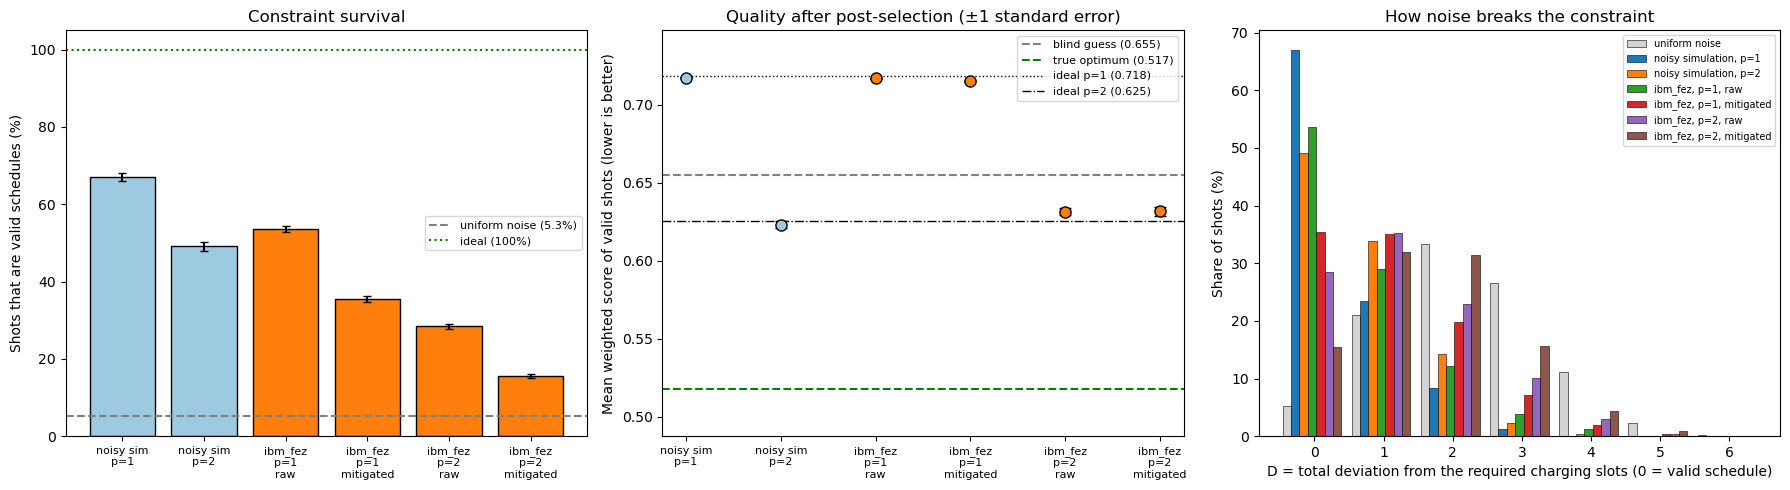

Best valid schedule seen on the QPU (p2_raw): 001111000110 | 9 shot(s) | score 0.5175 (optimum 0.5175) | (cost, peak, wear) = (11, 10, 4)
[[0 1 1 0]
 [0 0 1 1]
 [1 1 0 0]]
Caution: a schedule seen only 1-2 times is within what noise alone produces (about 1 shot per bitstring under uniform noise). Judge the QPU by the aggregate numbers above.


In [52]:
import matplotlib.pyplot as plt

measured = [r for r in summary_rows if 'feasible_se' in r]        # noisy simulation + QPU rows
if not measured:
    print("No measured runs yet: submit/fetch the QPU jobs above first.")
else:
    names = [r['label'].replace('QPU ', '').replace('noisy simulation', 'noisy sim').replace(', ', '\n') for r in measured]
    is_qpu = ['QPU' in r['label'] for r in measured]
    colors = ['#ff7f0e' if q else '#9ecae1' for q in is_qpu]
    xs = np.arange(len(measured))

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

    # (a) share of shots that are valid schedules
    ax1.bar(xs, [r['feasible_rate'] * 100 for r in measured], yerr=[r['feasible_se'] * 100 for r in measured],
            color=colors, edgecolor='black', capsize=3)
    ax1.axhline(RANDOM_FEASIBLE_RATE * 100, color='gray', ls='--', label='uniform noise (5.3%)')
    ax1.axhline(100, color='green', ls=':', label='ideal (100%)')
    ax1.set_xticks(xs); ax1.set_xticklabels(names, fontsize=8)
    ax1.set_ylabel('Shots that are valid schedules (%)'); ax1.set_title('Constraint survival'); ax1.legend(fontsize=8)

    # (b) quality of the valid shots only (post-selection)
    ok = [i for i, r in enumerate(measured) if 'post_mean' in r]
    for i in ok:    # points, not bars: the axis does not start at zero
        ax2.errorbar(i, measured[i]['post_mean'], yerr=measured[i]['post_mean_se'], fmt='o', ms=8,
                     color=colors[i], ecolor='black', capsize=4, mec='black')
    ax2.axhline(E_mean, color='gray', ls='--', label=f'blind guess ({E_mean:.3f})')
    ax2.axhline(E_best, color='green', ls='--', label=f'true optimum ({E_best:.3f})')
    for p, ls in ((1, ':'), (2, '-.')):
        e = next(r['post_mean'] for r in summary_rows if r['label'] == f'ideal simulation, p={p}')
        ax2.axhline(e, color='black', ls=ls, lw=1, label=f'ideal p={p} ({e:.3f})')
    lo = min([measured[i]['post_mean'] - measured[i]['post_mean_se'] for i in ok] + [E_best]) - 0.03
    hi = max([measured[i]['post_mean'] + measured[i]['post_mean_se'] for i in ok] + [E_mean]) + 0.03
    ax2.set_ylim(lo, hi)
    ax2.set_xticks(xs); ax2.set_xticklabels(names, fontsize=8)
    ax2.set_ylabel('Mean weighted score of valid shots (lower is better)')
    ax2.set_title('Quality after post-selection (±1 standard error)'); ax2.legend(fontsize=8)

    # (c) how far wrong are the invalid shots?
    groups = [('uniform noise', violation_hist(uniform), 'lightgray')]
    for r in measured:
        groups.append((r['label'].replace('QPU ', ''), violation_hist(sources[r['label']]), None))
    width = 0.85 / len(groups)
    for gi, (name, h, col) in enumerate(groups):
        ax3.bar(np.arange(len(h)) + gi * width, h * 100, width, label=name, color=col, edgecolor='black', lw=0.4)
    ax3.set_xticks(np.arange(len(groups[0][1])) + 0.4)
    ax3.set_xticklabels(range(len(groups[0][1])))
    ax3.set_xlabel('D = total deviation from the required charging slots (0 = valid schedule)')
    ax3.set_ylabel('Share of shots (%)'); ax3.set_title('How noise breaks the constraint'); ax3.legend(fontsize=7)

    plt.tight_layout()
    plt.savefig(f'{RESULTS}/hw_results_summary.png', dpi=150)
    plt.show()

    # best valid schedule seen on the QPU, re-scored classically
    best = None
    for rid, cnt in hw_counts.items():
        for k, v in cnt.items():
            x = bits_to_x(k)
            if is_feasible(inst, x):
                sc = float(x @ Q @ x + c)
                if best is None or (sc, -v) < (best[0], -best[1]):
                    best = (sc, v, k, rid, objectives(inst, x))
    if best:
        print(f"Best valid schedule seen on the QPU ({best[3]}): {best[2]} | {best[1]} shot(s) | score {best[0]:.4f} "
              f"(optimum {E_best:.4f}) | (cost, peak, wear) = {best[4]}")
        print(bits_to_x(best[2]).reshape(inst.V, inst.T))
        print("Caution: a schedule seen only 1-2 times is within what noise alone produces (about 1 shot per bitstring "
              "under uniform noise). Judge the QPU by the aggregate numbers above.")